### 1. Import required libraries

In [43]:
import rasterio                            # Read and process raster data (GeoTIFF files)
from rasterio.mask import mask             # Clip rasters using AOI boundaries
from rasterio.warp import reproject        # Reproject and align raster
import numpy as np                         # Perform numerical calculations and array operations
import matplotlib.pyplot as plt            # Create maps, charts, and visualizations
import os                                  #M anage files and folders
import geopandas as gpd                    # Read, analyze, and visualize vector GIS data
import libpysal                            # Create spatial weights and neighbor relationships.
import esda                                # Perform hotspot analysis and spatial statistics.
import pandas as pd                        # Work with tables and attribute data
from shapely.geometry import Point         # Create point geometries from coordinates

### 2. Load municipality boundary

In [44]:
# Read kommune boundaries
kommuner = gpd.read_file(
    r"C:\Users\ab\Desktop\QGIS\Variables_Norway\1_Kommune_Boundary_Norge\Kommune_Norge.gpkg"
)


# See columns
print(kommuner.columns)

Index(['objtype', 'samiskForvaltningsområde',
       'identifikasjon.Identifikasjon.lokalId',
       'identifikasjon.Identifikasjon.navnerom',
       'identifikasjon.Identifikasjon.versjonId', 'datafangstdato',
       'oppdateringsdato', 'datauttaksdato', 'opphav', 'kommunenummer',
       'administrativenhetnavn', 'kommunenavn', 'gyldigFra', 'gyldigTil',
       'geometry'],
      dtype='str')


C:\Users\ab\miniconda3\envs\habitat\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column oppdateringsdato, 2024-05-10T13:00:48+02:00, successfully parsed
  return ogr_read(


In [45]:
#View Kommunes
kommuner[["kommunenummer", "kommunenavn"]].head()

,kommunenummer,kommunenavn
0,3419,Våler
1,3326,Hemsedal
2,4622,Kvam
3,5054,Indre Fosen
4,4617,Kvinnherad


In [46]:
#Serach for Stavanger
kommuner[kommuner["kommunenavn"] == "Stavanger"]

,objtype,samiskForvaltningsområde,identifikasjon.Identifikasjon.lokalId,identifikasjon.Identifikasjon.navnerom,identifikasjon.Identifikasjon.versjonId,datafangstdato,oppdateringsdato,datauttaksdato,opphav,kommunenummer,administrativenhetnavn,kommunenavn,gyldigFra,gyldigTil,geometry
239,Kommune,False,837791de-4014-4e8a-a3de-ac2044befe2c,https://data.geonorge.no/sosi/inndelinger/innd...,16,None,2025-10-13 11:56:04+00:00,2025-12-10 15:42:07+01:00,None,1103,"[{""navn"":""Stavanger"",""rekkefolge"":""0"",""sprak"":...",Stavanger,20251013,None,"MULTIPOLYGON (((-33088.3 6600845.51, -36010.83..."


In [47]:
# Select municipality

kommune_name = "Stavanger"

kommune = kommuner[
    kommuner["kommunenavn"] == kommune_name
]

print(f"Selected municipality: {kommune_name}")

Selected municipality: Stavanger


### 3. Select Municipality

In [48]:
# Select municipality

kommune_name = "Stavanger"

kommune = kommuner[
    kommuner["kommunenavn"] == kommune_name
].copy()

print(f"Selected municipality: {kommune_name}")

Selected municipality: Stavanger


### 4. Load Dybdeareal Layer

In [49]:

# Load depth area polygons

dybde = gpd.read_file(
    r"C:\Users\ab\Desktop\QGIS\Variables_Norway\2_Dybdedata\Dybdedata_Norge.gdb",
    layer="dybdeareal"
)

print(f"Features loaded: {len(dybde)}")


Features loaded: 633786


### 5. Clip Dybdeareal to Municipality

In [50]:
# Make sure CRS match

if dybde.crs != kommune.crs:
    dybde = dybde.to_crs(kommune.crs)

# Clip

dybde_kommune = gpd.overlay(
    dybde,
    kommune,
    how="intersection"
)

print(f"Depth polygons in municipality: {len(dybde_kommune)}")

Depth polygons in municipality: 4200


### 6. Select 0-30 m Depth

In [51]:
dybde_0_30 = dybde_kommune[
    dybde_kommune["maksimumsdybde"] <= 30
].copy()

print(f"0-30 m polygons: {len(dybde_0_30)}")

0-30 m polygons: 3448


In [52]:
# Create final AOI
aoi = dybde_0_30.dissolve()

# Save AOI

output_path = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\AOI_NiN\AOI_Stavanger_0_30m.gpkg"

aoi.to_file(
    output_path,
    driver="GPKG"
)

print("AOI saved successfully!")
print(output_path)

AOI saved successfully!
C:\Users\ab\Desktop\Python\Stavanger_kommune\AOI_NiN\AOI_Stavanger_0_30m.gpkg


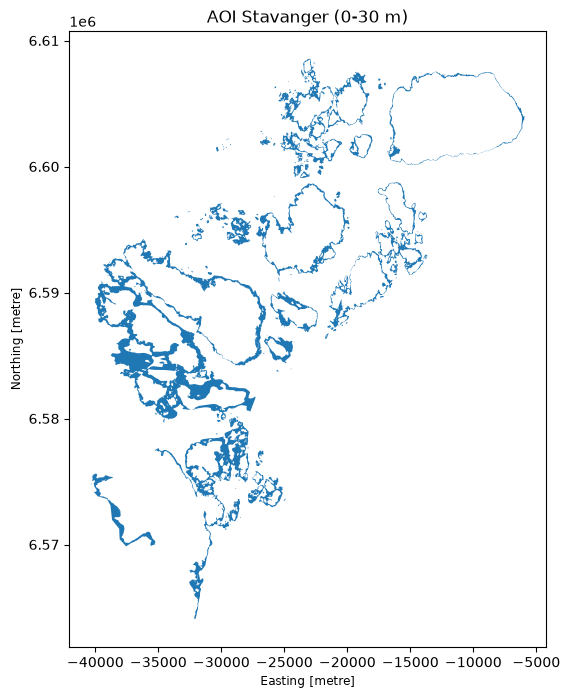

In [53]:
# Visualize AOI
aoi.plot(figsize=(8,8))
plt.title("AOI Stavanger (0-30 m)")
plt.show()

### 7. Clip Bathymetry to AOI

In [54]:
# Load AOI

aoi = gpd.read_file(
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\AOI_NiN\AOI_Stavanger_0_30m.gpkg"
)


C:\Users\ab\miniconda3\envs\habitat\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column datauttaksdato_2, 2025-12-10T15:42:07+01:00, successfully parsed
  return ogr_read(


In [55]:
# Bathymetry raster

bathymetry_path = (
   r"C:\Users\ab\Desktop\QGIS\Variables_Norway\3_Bathemetry\Stavanger_Geonorge_merged\Bathemetry_geonorge.tif"
)

In [56]:
# Clip raster

with rasterio.open(bathymetry_path) as src:

    clipped, transform = mask(
        src,
        aoi.geometry,
        crop=True
    )

    meta = src.meta.copy()

meta.update({
    "height": clipped.shape[1],
    "width": clipped.shape[2],
    "transform": transform
})

In [57]:
# Save clipped bathymetry

output_bathy = (
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\Bathymetry_Stavanger.tif"
)

with rasterio.open(
    output_bathy,
    "w",
    **meta
) as dest:
    dest.write(clipped)

print("Bathymetry clipped successfully!")
print(output_bathy)

Bathymetry clipped successfully!
C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\Bathymetry_Stavanger.tif


### 8. Check Bathymetry CRS and Resolution

In [58]:
with rasterio.open(output_bathy) as src:
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Width:", src.width)
    print("Height:", src.height)

CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890


### 9. Generate Seafloor Slope from Bathymetry

In [59]:

# Load bathymetry

with rasterio.open(output_bathy) as src:

    bathy = src.read(1).astype(float)

    transform = src.transform
    meta = src.meta.copy()

# Get cell size

cellsize_x = transform.a
cellsize_y = abs(transform.e)

# Calculate gradients

dz_dy, dz_dx = np.gradient(
    bathy,
    cellsize_y,
    cellsize_x
)

# Calculate slope in degrees

slope = np.degrees(
    np.arctan(
        np.sqrt(dz_dx**2 + dz_dy**2)
    )
)

# Update metadata

meta.update(
    dtype="float32"
)

print("Slope calculated successfully")

Slope calculated successfully


C:\Users\ab\AppData\Local\Temp\ipykernel_21040\1155009103.py:5: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  bathy = src.read(1).astype(float)


In [60]:
# Save Slope Raster
slope_output = (
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\Slope_Stavanger.tif"
)

with rasterio.open(
    slope_output,
    "w",
    **meta
) as dest:

    dest.write(
        slope.astype("float32"),
        1
    )

print("Slope raster saved successfully!")
print(slope_output)


Slope raster saved successfully!
C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\Slope_Stavanger.tif


### 10. Validate Slope Raster

In [61]:
with rasterio.open(slope_output) as src:

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Width:", src.width)
    print("Height:", src.height)

CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890


### 11. Visualize Bathymetry and Slope

C:\Users\ab\AppData\Local\Temp\ipykernel_21040\1070663082.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  bathy = src.read(1)
C:\Users\ab\AppData\Local\Temp\ipykernel_21040\1070663082.py:11: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  slope = src.read(1)


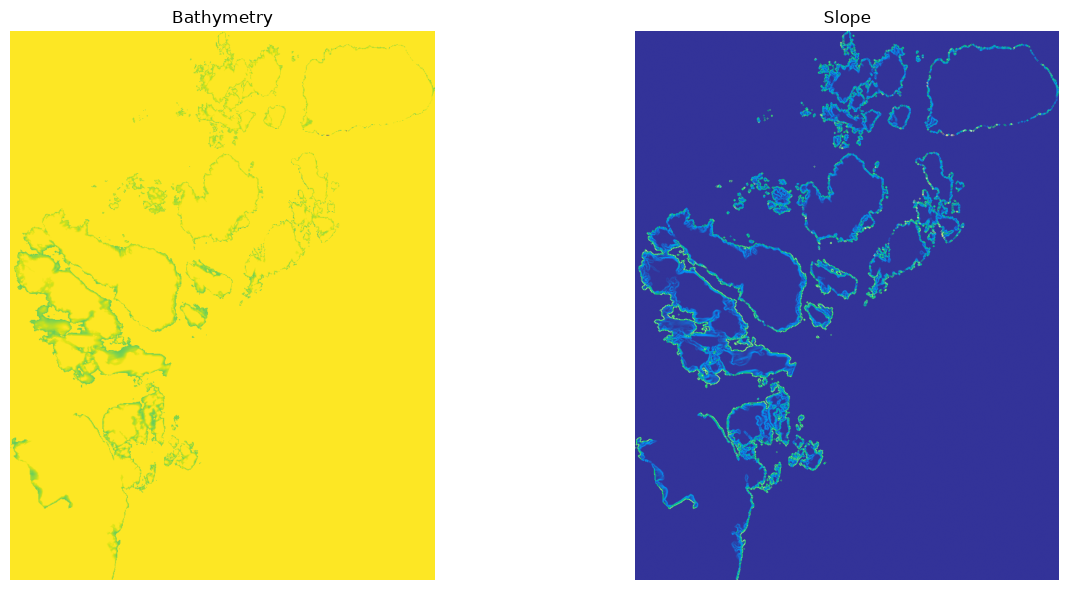

In [62]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

with rasterio.open(output_bathy) as src:
    bathy = src.read(1)

ax[0].imshow(bathy, cmap="viridis")
ax[0].set_title("Bathymetry")
ax[0].axis("off")

with rasterio.open(slope_output) as src:
    slope = src.read(1)

ax[1].imshow(slope, cmap="terrain")
ax[1].set_title("Slope")
ax[1].axis("off")

plt.tight_layout()
plt.show()

### 11. Create Function for Raster Clipping and Alignment

In [66]:


def clip_and_align_raster(
    input_raster,
    output_raster,
    aoi,
    reference_raster
):
    
    # Clip raster
    with rasterio.open(input_raster) as src:

        clipped, transform = mask(
            src,
            aoi.geometry,
            crop=True
        )

        clipped_meta = src.meta.copy()

        clipped_meta.update({
            "height": clipped.shape[1],
            "width": clipped.shape[2],
            "transform": transform
        })

    # Reference grid
    with rasterio.open(reference_raster) as ref:

        aligned = np.empty(
            (1, ref.height, ref.width),
            dtype=np.float32
        )

        reproject(
            source=clipped,
            destination=aligned,
            src_transform=transform,
            src_crs=clipped_meta["crs"],
            dst_transform=ref.transform,
            dst_crs=ref.crs,
            resampling=Resampling.bilinear
        )

        meta = ref.meta.copy()

        meta.update(
            dtype="float32",
            count=1
        )

    # Save
    with rasterio.open(
        output_raster,
        "w",
        **meta
    ) as dst:

        dst.write(
            aligned.astype("float32")
        )

    print(f"Saved: {output_raster}")


### 12. Clip and Align Wave Exposure

In [69]:
wave_input = r"C:\Users\ab\Desktop\QGIS\Variables_Norway\6_Wave_Exposuser_NiN\Wave_Exposure_Raster\boelgeeksponering_nin_basistrinn_norge_2004_25833.tif"

wave_output = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\Wave_Exposure_Stavanger.tif"

clip_and_align_raster(
    wave_input,
    wave_output,
    aoi,
    output_bathy
)

NameError: name 'Resampling' is not defined

In [67]:
# Validate Wave Exposure data after clipping
with rasterio.open(wave_output) as src:

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Width:", src.width)
    print("Height:", src.height)


CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890


### 13. Clip and Align Grain Size

In [68]:
grain_input = r"C:\Users\ab\Desktop\QGIS\Variables_Norway\4_Sediment_Data\Rasterize_grainsize_norge.tif"

grain_output = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\GrainSize_Stavanger.tif"

clip_and_align_raster(
    grain_input,
    grain_output,
    aoi,
    output_bathy
)

NameError: name 'Resampling' is not defined

In [42]:
# Validate grainsize
with rasterio.open(grain_output) as src:

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Width:", src.width)
    print("Height:", src.height)


NameError: name 'grain_output' is not defined

###  14. Clip and Align Light Attenuation

In [70]:
light_input = r"C:\Users\ab\Desktop\QGIS\Variables_Norway\8_Light attenuation_EMODnet\LightAttnuation_Norge_EPSG25833.tif"

light_output = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Variables\LightAttenuation_Stavanger.tif"

clip_and_align_raster(
    light_input,
    light_output,
    aoi,
    output_bathy
)

NameError: name 'Resampling' is not defined

In [71]:
# Validate Light Attenuation
with rasterio.open(light_output) as src:

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Width:", src.width)
    print("Height:", src.height)



CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890


### 15. Validate Environmental Variables

In [72]:
rasters = {
    "Bathymetry": output_bathy,
    "Slope": slope_output,
    "Wave Exposure": wave_output,
    "Grain Size": grain_output,
    "Light Attenuation": light_output
}

for name, raster in rasters.items():

    with rasterio.open(raster) as src:

        print(f"\n{name}")
        print("-" * 30)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Width:", src.width)
        print("Height:", src.height)


Bathymetry
------------------------------
CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890

Slope
------------------------------
CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890

Wave Exposure
------------------------------
CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890

Grain Size
------------------------------
CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890

Light Attenuation
------------------------------
CRS: EPSG:25833
Resolution: (50.0, 50.0)
Width: 689
Height: 890


### 16. Visualize Environmental Variables

C:\Users\ab\AppData\Local\Temp\ipykernel_21040\4057290154.py:14: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  data = src.read(1)


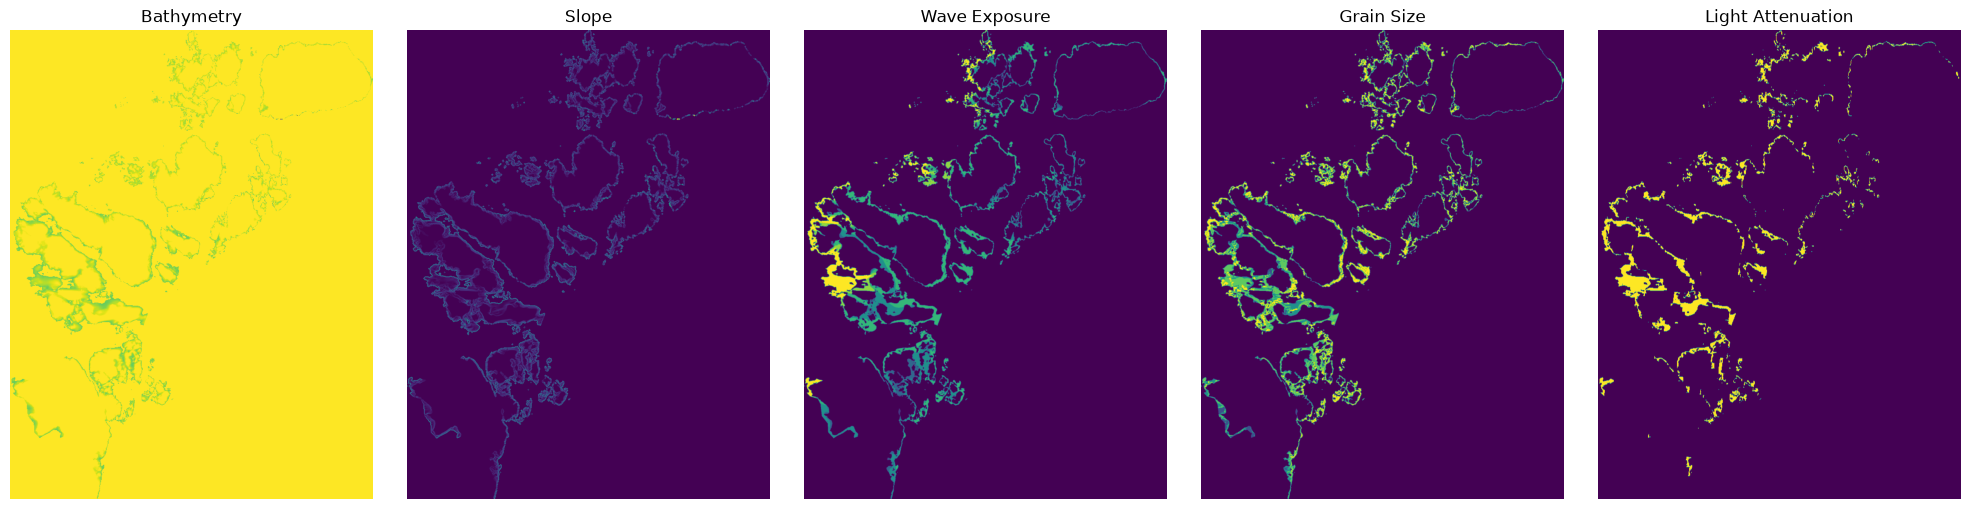

In [73]:
variables = {
    "Bathymetry": output_bathy,
    "Slope": slope_output,
    "Wave Exposure": wave_output,
    "Grain Size": grain_output,
    "Light Attenuation": light_output
}

fig, axes = plt.subplots(1, 5, figsize=(20,5))

for ax, (name, raster) in zip(axes, variables.items()):

    with rasterio.open(raster) as src:
        data = src.read(1)

    ax.imshow(data)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 17. Define Habitat Suitability Criteria

This section defines the environmental requirements used to model potential marine habitat distribution. Suitability criteria are based on environmental predictors including bathymetry, slope, wave exposure, grain size, and light attenuation.
 
The following habitat groups will be modelled:
 
- Topographic Habitats
- Shell Habitats
- Seagrass and Coastal Vegetation Habitats
- Kelp Forest Habitats
 
Each habitat model will produce a binary suitability raster where:
 
- 1 = Suitable
- 0 = Unsuitable

In [74]:
# Habitat suitability criteria

habitats = {

    # Topographic habitats

    "NT01_Littoralbassengbunn": {
        "depth_min": -5,
        "depth_max": 0,
        "wave_max": 2
    },

    "NT05_Tidevannsmudderflate": {
        "depth_min": -2,
        "depth_max": 0,
        "substrate": [2]
    },

    "NT06_Sublitoral_Grunn_Sandbunn": {
        "depth_min": -30,
        "depth_max": -1,
        "substrate": [3]
    },

    # Shell habitats

    "NT07_Flatostersbunn": {
        "depth_min": -30,
        "depth_max": -1,
        "substrate": [3, 4],
        "wave_max": 4
    },

    "NT08_Skjellbunn": {
        "depth_min": -30,
        "depth_max": -1,
        "substrate": [4]
    },

    # Seagrass habitats

    "NT09_Marin_Tidevannssump": {
        "depth_min": -2,
        "depth_max": 0,
        "wave_max": 2
    },

    "NT10_Alegrasbunn": {
        "depth_min": -10,
        "depth_max": 0,
        "substrate": [3],
        "wave_max": 3
    },

    "NT11_Dvergalegrasbunn": {
        "depth_min": -5,
        "depth_max": 0,
        "substrate": [3],
        "wave_max": 2
    },

    "NT13_Brakkvanns_Undervannseng": {
        "depth_min": -5,
        "depth_max": 0,
        "wave_max": 2
    },

    # Kelp habitats

    "NT14_Sukkertareskog": {
        "depth_min": -30,
        "depth_max": -2,
        "wave_min": 2,
        "substrate": [1, 4]
    },

    "NT16_Stortareskog": {
        "depth_min": -30,
        "depth_max": -2,
        "wave_min": 4,
        "substrate": [1, 4]
    },

    "NT18_Fingertareskog": {
        "depth_min": -20,
        "depth_max": -1,
        "wave_min": 4,
        "substrate": [1, 4]
    },

    "NT20_Butareskog": {
        "depth_min": -15,
        "depth_max": -1,
        "wave_min": 5,
        "substrate": [1, 4]
    },

    "NT30_Sterke_Tidevannsstrømmer": {
        "depth_min": -30,
        "depth_max": 0,
        "wave_min": 5
    }
}

##### Grain Size Classes (for Stavanger)


### Grain Size Classification

| Class | Description |
|---------|-------------|
| 1 | Hard Bottom / Bedrock |
| 2 | Mud |
| 3 | Sand |
| 4 | Coarse Sediment (gravel, stone, boulders) |


### 18. Load Environmental Variables for Habitat Modelling

In [75]:
# Load bathymetry

with rasterio.open(output_bathy) as src:
    depth = src.read(1)

# Load slope

with rasterio.open(slope_output) as src:
    slope = src.read(1)

# Load wave exposure

with rasterio.open(wave_output) as src:
    wave = src.read(1)

# Load grain size

with rasterio.open(grain_output) as src:
    grain = src.read(1)

# Load light attenuation

with rasterio.open(light_output) as src:
    light = src.read(1)

print("Environmental variables loaded successfully")

Environmental variables loaded successfully


C:\Users\ab\AppData\Local\Temp\ipykernel_21040\3536785954.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  depth = src.read(1)
C:\Users\ab\AppData\Local\Temp\ipykernel_21040\3536785954.py:9: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  slope = src.read(1)
C:\Users\ab\AppData\Local\Temp\ipykernel_21040\3536785954.py:14: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  wave = src.read(1)
C:\Users\ab\AppData\Local\Temp\ipykernel_21040\3536785954.py:19: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view usi

### 19. Verify Raster Dimensions

In [76]:
print("Depth:", depth.shape)
print("Slope:", slope.shape)
print("Wave:", wave.shape)
print("Grain:", grain.shape)
print("Light:", light.shape)

Depth: (890, 689)
Slope: (890, 689)
Wave: (890, 689)
Grain: (890, 689)
Light: (890, 689)


### 20. Create Output Folder for Habitat Suitability Maps

In [77]:
import os

suitability_folder = (
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\suitability_analysis"
)

os.makedirs(
    suitability_folder,
    exist_ok=True
)

print("Output folder ready")

Output folder ready


### 21. Explore Environmental Variables

In [78]:
variables = {
    "Depth": depth,
    "Slope": slope,
    "Wave": wave,
    "Grain": grain,
    "Light": light
}

for name, data in variables.items():

    print("\n", name)
    print("Minimum:", np.nanmin(data))
    print("Maximum:", np.nanmax(data))


 Depth
Minimum: -125.72
Maximum: 0.0

 Slope
Minimum: 0.0
Maximum: 51.70378

 Wave
Minimum: 0.0
Maximum: 6.0

 Grain
Minimum: 0.0
Maximum: 4.0

 Light
Minimum: -3.4028235e+38
Maximum: 0.4765928


In [ ]:
# check how much is deeper than -30 m


In [79]:
print("Pixels deeper than -30 m:")
print(np.sum(depth < -30))

Pixels deeper than -30 m:
408


In [80]:
# Keep only depths between 0 and -30 m

depth = np.where(
    (depth >= -30) & (depth <= 0),
    depth,
    np.nan
)

print("Minimum:", np.nanmin(depth))
print("Maximum:", np.nanmax(depth))

Minimum: -30.0
Maximum: 0.0


In [81]:
# Remove NoData values from light attenuation

light = np.where(
    light < -1e30,
    np.nan,
    light
)

print("Light Min:", np.nanmin(light))
print("Light Max:", np.nanmax(light))

Light Min: 0.11881787
Light Max: 0.4765928


In [82]:
print("Depth Min:", np.nanmin(depth))
print("Depth Max:", np.nanmax(depth))

print("Light Min:", np.nanmin(light))
print("Light Max:", np.nanmax(light))

Depth Min: -30.0
Depth Max: 0.0
Light Min: 0.11881787
Light Max: 0.4765928


### 22. Create Suitability Analysis Folder

In [83]:
import os

suitability_folder = (
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\suitability_analysis"
)

os.makedirs(
    suitability_folder,
    exist_ok=True
)

print("Folder ready")

Folder ready


### 23. Save Reference Metadata

In [85]:
with rasterio.open(output_bathy) as src:

    suitability_meta = src.meta.copy()

suitability_meta.update(
    dtype="uint8",
    count=1,
    nodata=0
)


### 24.Create Function to Save Habitat Rasters

In [86]:
def save_habitat_raster(array, habitat_name):

    output_file = os.path.join(
        suitability_folder,
        f"{habitat_name}.tif"
    )

    with rasterio.open(
        output_file,
        "w",
        **suitability_meta
    ) as dst:

        dst.write(
            array.astype("uint8"),
            1
        )

    print(f"Saved: {habitat_name}")

## 22. Suitability Models

In [ ]:
# Create the helper function

In [87]:
def habitat_model(condition):
    return np.where(condition, 1, 0)

### 22(A) Kelp Group:

In [88]:
habitats = {}

# -------------------
# KELP
# -------------------

habitats["NT03"] = habitat_model(
    (depth >= -2) &
    (depth <= 0) &
    (slope >= 1) &
    ((grain == 1) | (grain == 4)) &
    (light <= 0.35) &
    (wave >= 2) &
    (wave <= 6)
)

habitats["NT14"] = habitat_model(
    (depth >= -30) &
    (depth <= -1) &
    (slope >= 1) &
    ((grain == 1) | (grain == 4)) &
    (light <= 0.35) &
    (wave >= 2) &
    (wave <= 5)
)

habitats["NT16"] = habitat_model(
    (depth >= -30) &
    (depth <= -1) &
    (slope >= 2) &
    ((grain == 1) | (grain == 4)) &
    (light <= 0.30) &
    (wave >= 5)
)

habitats["NT18"] = habitat_model(
    (depth >= -15) &
    (depth <= -1) &
    (slope >= 2) &
    ((grain == 1) | (grain == 4)) &
    (light <= 0.30) &
    (wave >= 4) &
    (wave <= 6)
)

habitats["NT20"] = habitat_model(
    (depth >= -10) &
    (depth <= -1) &
    (slope >= 2) &
    ((grain == 1) | (grain == 4)) &
    (light <= 0.30) &
    (wave >= 5)
)

habitats["NT21"] = habitat_model(
    (depth >= -30) &
    (depth <= -5) &
    (wave >= 2) &
    (wave <= 6) &
    (light <= 0.35) &
    (slope <= 10)
)

print("Habitats created:", len(habitats))
print(habitats.keys())

Habitats created: 6
dict_keys(['NT03', 'NT14', 'NT16', 'NT18', 'NT20', 'NT21'])


#### Save Kelp Group

In [ ]:
## true binary (0 and 1 visible)

In [94]:
suitability_meta.update(
    dtype="uint8",
    count=1
)

# remove nodata
if "nodata" in suitability_meta:
    suitability_meta.pop("nodata")

In [95]:
# Save kelp habitats with true binary values

for habitat_name, habitat_array in habitats.items():

    output_file = os.path.join(
        kelp_folder,
        f"{habitat_name}.tif"
    )

    with rasterio.open(
        output_file,
        "w",
        **suitability_meta
    ) as dst:

        dst.write(
            habitat_array.astype("uint8"),
            1
        )

    print(f"Saved: {habitat_name}")

print("Kelp habitats re-saved successfully!")

Saved: NT03
Saved: NT14
Saved: NT16
Saved: NT18
Saved: NT20
Saved: NT21
Kelp habitats re-saved successfully!


### 22(B) Seagrass Group:

In [97]:
# -------------------
# SEAGRASS
# -------------------

seagrass = {}

seagrass["NT09"] = habitat_model(
    (depth >= -3) &
    (depth <= 1) &
    ((grain == 2) | (grain == 3)) &
    (wave <= 4) &
    (slope <= 10)
)

seagrass["NT10"] = habitat_model(
    (depth >= -10) &
    (depth <= -0.5) &
    ((grain == 2) | (grain == 3)) &
    (wave <= 4) &
    (slope <= 5) &
    (light <= 0.35)
)

seagrass["NT11"] = habitat_model(
    (depth >= -2) &
    (depth <= 0) &
    ((grain == 2) | (grain == 3)) &
    (wave <= 3) &
    (slope <= 3) &
    (light <= 0.35)
)

seagrass["NT13"] = habitat_model(
    (depth >= -5) &
    (depth <= 0) &
    ((grain == 2) | (grain == 3)) &
    (wave <= 3) &
    (slope <= 5) &
    (light <= 0.35)
)

seagrass["NT32"] = habitat_model(
    (depth >= -10) &
    ((grain == 2) | (grain == 3)) &
    (wave <= 4) &
    (slope <= 10) &
    (light <= 0.35)
)

print("Seagrass habitats created:", len(seagrass))

for name, raster in seagrass.items():
    print(name, np.sum(raster))


Seagrass habitats created: 5
NT09 22
NT10 180
NT11 0
NT13 16
NT32 224


#### Save Seagrass Group

In [98]:
seagrass_folder = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\suitability_analysis\Seagrass"

os.makedirs(seagrass_folder, exist_ok=True)

for habitat_name, habitat_array in seagrass.items():

    output_file = os.path.join(
        seagrass_folder,
        f"{habitat_name}.tif"
    )

    with rasterio.open(
        output_file,
        "w",
        **suitability_meta
    ) as dst:

        dst.write(
            habitat_array.astype("uint8"),
            1
        )

    print(f"Saved: {habitat_name}")

print("Seagrass group saved successfully!")

Saved: NT09
Saved: NT10
Saved: NT11
Saved: NT13
Saved: NT32
Seagrass group saved successfully!


### 22(C) Shell Group:

In [110]:
# -------------------
# SHELL
# -------------------

shell = {}

shell["NT02"] = habitat_model(
    (depth >= -5) &
    (depth <= 0) &
    ((grain == 1) | (grain == 4)) &
    (wave >= 2) &
    (wave <= 6)
)

shell["NT07"] = habitat_model(
    (depth >= -30) &
    (depth <= -2) &
    ((grain == 2) | (grain == 3)) &
    (wave >= 2)
)

shell["NT08"] = habitat_model(
    (depth >= -30) &
    ((grain == 2) | (grain == 3)) &
    (wave >= 4)
)

print("Shell habitats created:", len(shell))

for name, raster in shell.items():
    print(name, np.sum(raster))

Shell habitats created: 3
NT02 130
NT07 2881
NT08 2058


#### Save Shell Group

In [111]:
shell_folder = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\suitability_analysis\Shell"

os.makedirs(shell_folder, exist_ok=True)

for habitat_name, habitat_array in shell.items():

    output_file = os.path.join(
        shell_folder,
        f"{habitat_name}.tif"
    )

    with rasterio.open(
        output_file,
        "w",
        **suitability_meta
    ) as dst:

        dst.write(
            habitat_array.astype("uint8"),
            1
        )

    print(f"Saved: {habitat_name}")

print("Shell group saved successfully!")

Saved: NT02
Saved: NT07
Saved: NT08
Shell group saved successfully!


### 22(D) Topography Group:

In [99]:
# -------------------
# TOPOGRAPHY
# -------------------

topography = {}

topography["NT01"] = habitat_model(
    (depth >= -1) &
    (depth <= 1) &
    ((grain == 1) | (grain == 4)) &
    (wave <= 3)
)

topography["NT04"] = habitat_model(
    (depth >= -2) &
    (depth <= 1) &
    ((grain == 1) | (grain == 4)) &
    (slope >= 10)
)

topography["NT05"] = habitat_model(
    (depth >= -3) &
    ((grain == 2) | (grain == 3)) &
    (wave <= 4)
)

topography["NT06"] = habitat_model(
    (depth >= -15) &
    (grain == 3)
)

topography["NT22"] = habitat_model(
    (depth >= -5) &
    ((grain == 1) | (grain == 4)) &
    (slope >= 10)
)

topography["NT29"] = habitat_model(
    (depth <= -2) &
    ((grain == 1) | (grain == 4)) &
    (slope >= 5)
)

topography["NT30"] = habitat_model(
    (depth >= -30) &
    (depth <= 0) &
    (wave >= 5)
)

print("Topography habitats created:", len(topography))

for name, raster in topography.items():
    print(name, np.sum(raster))

Topography habitats created: 7
NT01 0
NT04 0
NT05 22
NT06 1277
NT22 10
NT29 1035
NT30 5952


#### Save Topography Group

In [100]:
topography_folder = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\suitability_analysis\Topography"

os.makedirs(topography_folder, exist_ok=True)

for habitat_name, habitat_array in topography.items():

    output_file = os.path.join(
        topography_folder,
        f"{habitat_name}.tif"
    )

    with rasterio.open(
        output_file,
        "w",
        **suitability_meta
    ) as dst:

        dst.write(
            habitat_array.astype("uint8"),
            1
        )

    print(f"Saved: {habitat_name}")

print("Topography group saved successfully!")

Saved: NT01
Saved: NT04
Saved: NT05
Saved: NT06
Saved: NT22
Saved: NT29
Saved: NT30
Topography group saved successfully!


## 23. Richness Maps

#### 23(A) Kelp Richness Map:

In [101]:
kelp_richness = (
    habitats["NT03"] +
    habitats["NT14"] +
    habitats["NT16"] +
    habitats["NT18"] +
    habitats["NT20"] +
    habitats["NT21"]
)

print("Kelp Richness")
print("Min:", kelp_richness.min())
print("Max:", kelp_richness.max())

Kelp Richness
Min: 0
Max: 5


##### Save Klep Richness Map

In [102]:
output_file = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Kelp_Richness.tif"

os.makedirs(
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness",
    exist_ok=True
)

with rasterio.open(
    output_file,
    "w",
    **suitability_meta
) as dst:

    dst.write(
        kelp_richness.astype("uint8"),
        1
    )

print("Kelp Richness saved")

Kelp Richness saved


#### 23(B) Seagrass Richness Map:

In [103]:
seagrass_richness = (
    seagrass["NT09"] +
    seagrass["NT10"] +
    seagrass["NT11"] +
    seagrass["NT13"] +
    seagrass["NT32"]
)

print("Seagrass Richness")
print("Min:", seagrass_richness.min())
print("Max:", seagrass_richness.max())

Seagrass Richness
Min: 0
Max: 4


##### Save Seagrass Richness Map

In [104]:
output_file = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Seagrass_Richness.tif"

with rasterio.open(
    output_file,
    "w",
    **suitability_meta
) as dst:

    dst.write(
        seagrass_richness.astype("uint8"),
        1
    )

print("Seagrass Richness saved")

Seagrass Richness saved


#### 23(C) Shell Richness Map:

In [117]:
shell_richness = (
    shell["NT02"] +
    shell["NT07"] +
    shell["NT08"]
)

print("Shell Richness")
print("Min:", shell_richness.min())
print("Max:", shell_richness.max())

Shell Richness
Min: 0
Max: 2


##### Save Shell Richness Map

In [118]:
output_file = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Shell_Richness.tif"

with rasterio.open(
    output_file,
    "w",
    **suitability_meta
) as dst:

    dst.write(
        shell_richness.astype("uint8"),
        1
    )

print("Shell Richness saved")

Shell Richness saved


#### 23(D) Topography Richness Map:

In [108]:
topography_richness = (
    topography["NT01"] +
    topography["NT04"] +
    topography["NT05"] +
    topography["NT06"] +
    topography["NT22"] +
    topography["NT29"] +
    topography["NT30"]
)

print("Topography Richness")
print("Min:", topography_richness.min())
print("Max:", topography_richness.max())

Topography Richness
Min: 0
Max: 3


##### Save Topography Richness Map

In [109]:
output_file = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Topography_Richness.tif"

with rasterio.open(
    output_file,
    "w",
    **suitability_meta
) as dst:

    dst.write(
        topography_richness.astype("uint8"),
        1
    )

print("Topography Richness saved")

Topography Richness saved


## 24. Visualize Richness Maps

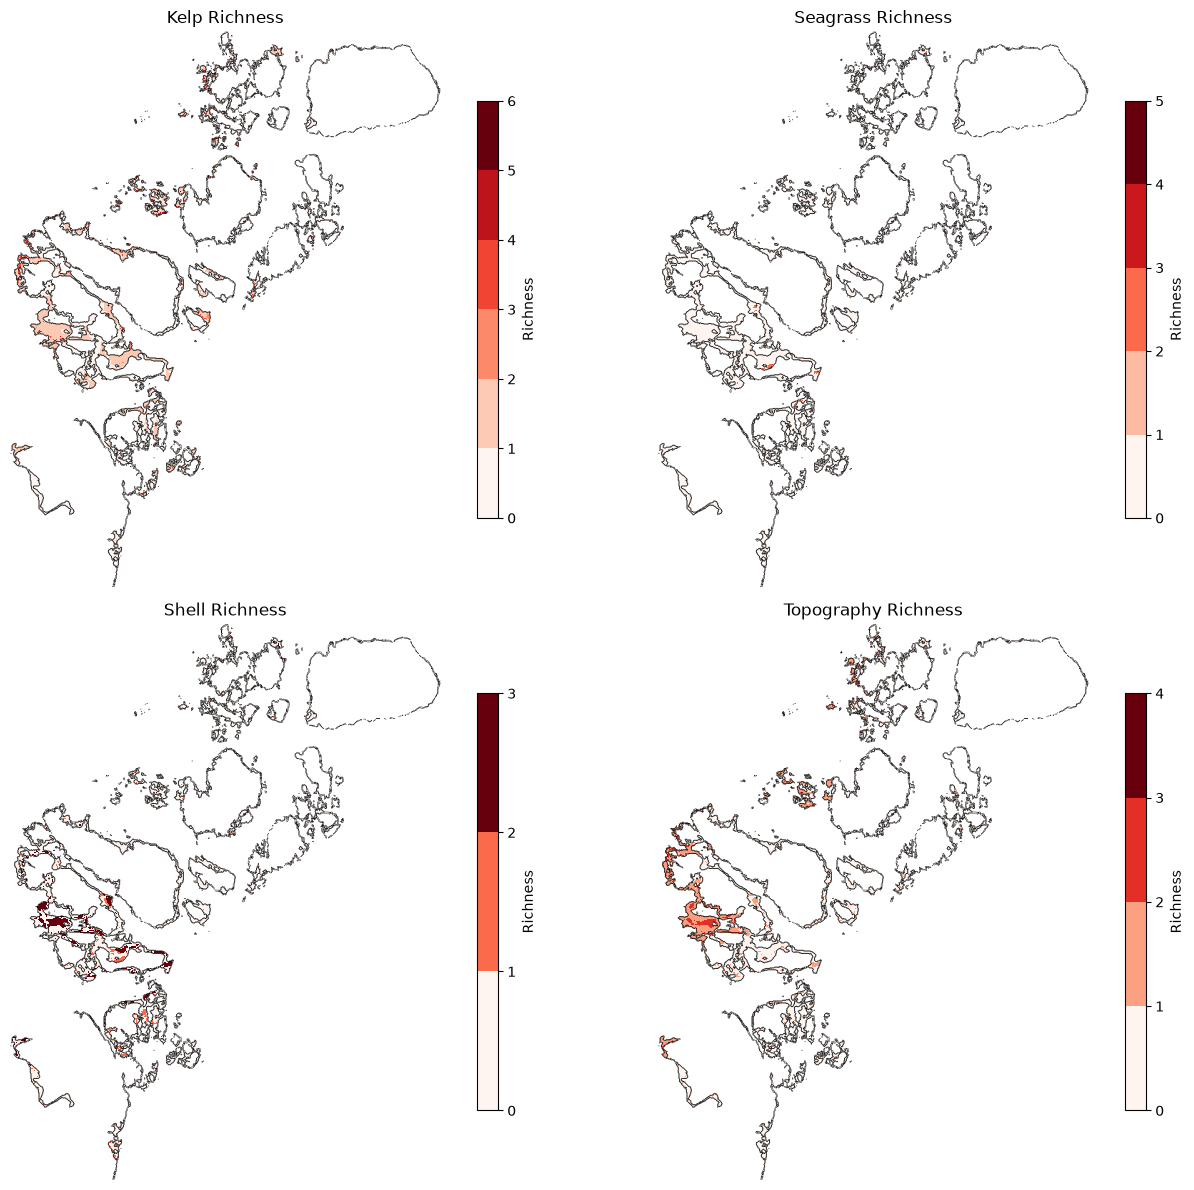

In [153]:
# -------------------
# VISUALIZE RICHNESS MAPS WITH AOI OUTLINE
# -------------------

from scipy import ndimage
from matplotlib.colors import BoundaryNorm

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

richness_maps = {
    "Kelp Richness": kelp_richness_masked,
    "Seagrass Richness": seagrass_richness_masked,
    "Shell Richness": shell_richness_masked,
    "Topography Richness": topography_richness_masked
}

# AOI boundary from raster mask
aoi_edge = aoi_mask ^ ndimage.binary_erosion(aoi_mask)

for ax, (title, raster) in zip(axes.flatten(), richness_maps.items()):

    masked_raster = np.ma.masked_invalid(raster)

    vmax = np.nanmax(raster)

    levels = np.arange(0, vmax + 2)

    norm = BoundaryNorm(
        levels,
        ncolors=256
    )

    im = ax.imshow(
        masked_raster,
        cmap="Reds",
        norm=norm,
        interpolation="nearest"
    )

    # AOI outline
    ax.contour(
        aoi_edge,
        levels=[0.5],
        colors="black",
        linewidths=0.3
    )

    ax.set_title(title, fontsize=12)
    ax.axis("off")

    plt.colorbar(
        im,
        ax=ax,
        shrink=0.75,
        label="Richness"
    )

plt.tight_layout()
plt.show()

### 24(A) Save Richness Maps as png

In [154]:
# Save BEFORE plt.show()

plt.tight_layout()

output_png = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Richness_Maps.png"

fig.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Saved:", output_png)

plt.show()

Saved: C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Richness_Maps.png


<Figure size 640x480 with 0 Axes>

## 25.Final Habitat Hotspot Map

In [142]:
# -------------------
# FINAL HABITAT HOTSPOT MAP
# -------------------

final_hotspot = (
    kelp_richness_masked +
    seagrass_richness_masked +
    shell_richness_masked +
    topography_richness_masked
)

print("Final Hotspot")

print("Minimum:", np.nanmin(final_hotspot))
print("Maximum:", np.nanmax(final_hotspot))

Final Hotspot
Minimum: 0.0
Maximum: 7.0


#### 25 (A) Visualize Final Habitat Hotspot Map

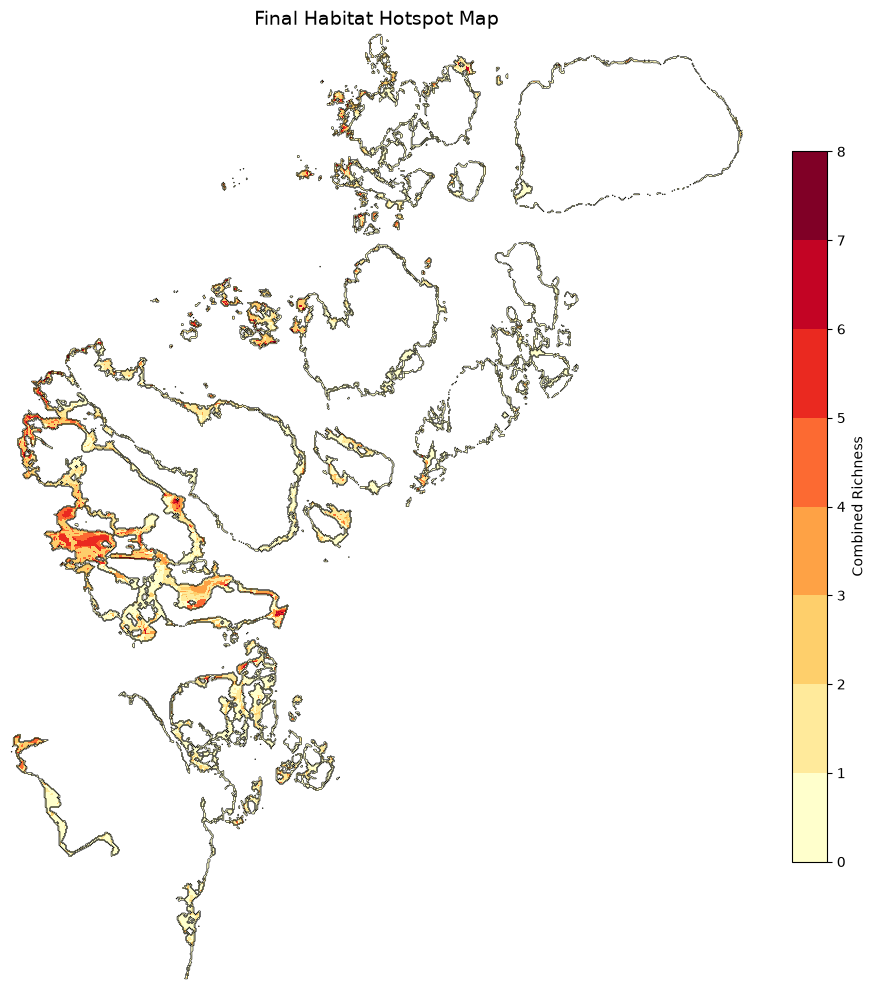

In [147]:
# -------------------
# VISUALIZE FINAL HOTSPOT MAP
# -------------------

from scipy import ndimage
from matplotlib.colors import BoundaryNorm

fig, ax = plt.subplots(figsize=(10, 10))

hotspot_masked = np.ma.masked_invalid(final_hotspot)

aoi_edge = aoi_mask ^ ndimage.binary_erosion(aoi_mask)

vmax = int(np.nanmax(final_hotspot))

levels = np.arange(0, vmax + 2)

norm = BoundaryNorm(
    levels,
    ncolors=256
)

im = ax.imshow(
    hotspot_masked,
    cmap="YlOrRd",
    norm=norm,
    interpolation="nearest"
)

ax.contour(
    aoi_edge,
    levels=[0.5],
    colors="black",
    linewidths=0.4
)

ax.set_title(
    "Final Habitat Hotspot Map",
    fontsize=14
)

ax.axis("off")

plt.colorbar(
    im,
    ax=ax,
    shrink=0.75,
    label="Combined Richness"
)

plt.tight_layout()
plt.show()

#### 25 (B) Save Final Habitat Hotspot Map

In [149]:
# -------------------
# SAVE FINAL HOTSPOT
# -------------------

hotspot_meta = suitability_meta.copy()

hotspot_meta.update(
    dtype="float32",
    nodata=-9999
)

hotspot_save = np.where(
    np.isnan(final_hotspot),
    -9999,
    final_hotspot
)

output_file = (
    r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Final_Habitat_Hotspot.tif"
)

with rasterio.open(
    output_file,
    "w",
    **hotspot_meta
) as dst:

    dst.write(
        hotspot_save.astype("float32"),
        1
    )

print("Final Habitat Hotspot saved successfully!")

Final Habitat Hotspot saved successfully!


#### 25 (C) Save Final Hotspot Map as png

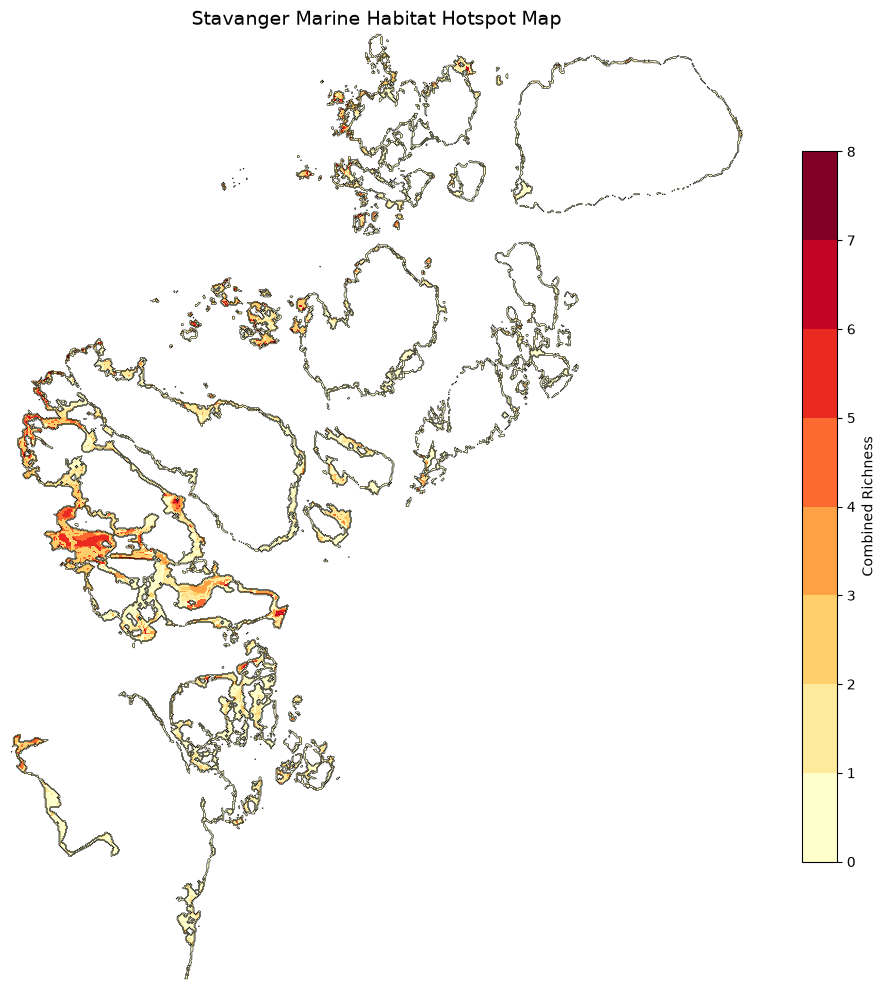

PNG saved:
C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Final_Habitat_Hotspot.png


In [150]:


fig, ax = plt.subplots(figsize=(12, 10))

hotspot_masked = np.ma.masked_invalid(final_hotspot)

aoi_edge = aoi_mask ^ ndimage.binary_erosion(aoi_mask)

vmax = int(np.nanmax(final_hotspot))

levels = np.arange(0, vmax + 2)

norm = BoundaryNorm(
    levels,
    ncolors=256
)

im = ax.imshow(
    hotspot_masked,
    cmap="YlOrRd",
    norm=norm,
    interpolation="nearest"
)

ax.contour(
    aoi_edge,
    levels=[0.5],
    colors="black",
    linewidths=0.4
)

ax.set_title(
    "Stavanger Marine Habitat Hotspot Map",
    fontsize=14
)

ax.axis("off")

plt.colorbar(
    im,
    ax=ax,
    shrink=0.75,
    label="Combined Richness"
)

plt.tight_layout()

# Save image
output_png = r"C:\Users\ab\Desktop\Python\Stavanger_kommune\Richness\Final_Habitat_Hotspot.png"

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("PNG saved:")
print(output_png)